Рассматриветм следующее выражение: 
$$\sum_{n=1}^{10000} \frac{(-1)^n}{n}$$

Очевидно, что его можно представить, как:
$$\sum_{n=1}^{10000} \frac{(-1)^n}{n} = \frac{(-1)^{n_1}}{n_1} + \frac{(-1)^{n_2}}{n_2} + \frac{(-1)^{n_3}}{n_3} + ... + \frac{(-1)^{n_n}}{n_n}$$

Давайте отсортируем числа и проведем суммирование последовательно так, что получим 4 случая:

**от больших чисел к малым**

**от малых чисел к большим**

**от больших к малым (отрицательные и положительные суммируем отдельно)**

**от малых к большим (отрицательные и положительные суммируем отдельно)**



Напишем функцию вычисления значения

In [1]:
def f(n):
    return ( (-1) ** n) / n

print(f(1))
print(f(2))
print(f(3))


-1.0
0.5
-0.3333333333333333


Уже здесь можно видеть непредставимость бесконечных дробей в памяти компьютера, однако мы продолжим.

Внесем все значения, которые выдаст функция в один общий список

In [2]:
common_list = [f(n) for n in range(1, 10000 + 1)]
print(len(common_list)) #проверим, что элементов действительно 1000

10000


Интереса ради посмотрим, что касательно суммы этого ряда считает Python:

In [3]:
print(f"Сумма ряда с точки зрения Python = {sum(common_list)}")

Python_sum = sum(common_list)

Сумма ряда с точки зрения Python = -0.6930971830599453


### Случай 1
#### (от больших чисел к малым)

In [4]:
big_numbers = sorted(common_list, key=abs, reverse=True)

print(big_numbers[0:10])

[-1.0, 0.5, -0.3333333333333333, 0.25, -0.2, 0.16666666666666666, -0.14285714285714285, 0.125, -0.1111111111111111, 0.1]


Действительно, в начале списка у нас положительные числа, причем в виде убывающей последовательности.

Взглянем на сумму этого ряда!

In [5]:
first_case_sum = 0
for i in range(len(big_numbers)):
    first_case_sum += big_numbers[i]

print(f"Сумма ряда в первом случае: {first_case_sum}")

Сумма ряда в первом случае: -0.6930971830599583


Уже видим расхождения...

### Случай 2
#### (от малых чисел к большим)

In [6]:
small_numbers = sorted(common_list, key=abs, reverse=False)

print(small_numbers[0:10])

[0.0001, -0.00010001000100010001, 0.00010002000400080016, -0.00010003000900270081, 0.00010004001600640257, -0.00010005002501250626, 0.00010006003602161297, -0.00010007004903432403, 0.00010008006405124099, -0.00010009008107296567]


In [7]:
second_case_sum = 0

for i in range(len(small_numbers)):
    second_case_sum += small_numbers[i]

print(f"Сумма ряда во втором случае: {second_case_sum}")

Сумма ряда во втором случае: -0.6930971830599453


### Случай 3
#### (от больших чисел к малым (раздельное суммирование отрицательных и положительных чисел))

In [8]:
positive_numbers = [common_list[i] for i in range(len(common_list)) if common_list[i] > 0]

negative_numbers = [common_list[i] for i in range(len(common_list)) if common_list[i] < 0]

positive_numbers = sorted(positive_numbers, key=abs, reverse=True)

negative_numbers = sorted(negative_numbers, key=abs, reverse=True)

print("Positive sorted head (most close to one):")
print(positive_numbers[0:5])

print()

print("Negative sorted head (most close to zero):")
print(negative_numbers[0:5])

Positive sorted head (most close to one):
[0.5, 0.25, 0.16666666666666666, 0.125, 0.1]

Negative sorted head (most close to zero):
[-1.0, -0.3333333333333333, -0.2, -0.14285714285714285, -0.1111111111111111]


In [9]:
third_case_positive_sum = 0

for i in range(len(positive_numbers)):
    third_case_positive_sum += positive_numbers[i]

third_case_negative_sum = 0

for i in range(len(negative_numbers)):
    third_case_negative_sum += negative_numbers[i]

third_case_sum = third_case_positive_sum + third_case_negative_sum

print(f"Положительная сумма ряда в третьем случае: {third_case_positive_sum}")
print(f"Отрицательная сумма ряда в третьем случае: {third_case_negative_sum}")
print(f"Сумма ряда в третьем случае: {third_case_sum}")

Положительная сумма ряда в третьем случае: 4.547254426492202
Отрицательная сумма ряда в третьем случае: -5.240351609552156
Сумма ряда в третьем случае: -0.6930971830599537


### Случай 4
#### (от малых чисел к большим (раздельное суммирование отрицательных и положительных чисел))

In [10]:
positive_numbers_2 = [common_list[i] for i in range(len(common_list)) if common_list[i] > 0]

negative_numbers_2 = [common_list[i] for i in range(len(common_list)) if common_list[i] < 0]

positive_numbers_2 = sorted(positive_numbers_2, key=abs, reverse=False)

negative_numbers_2 = sorted(negative_numbers_2, key=abs, reverse=False)

print("Positive sorted head (most close to zero):")
print(positive_numbers_2[0:5])

print()

print("Negative sorted head (most close to minus one):")
print(negative_numbers_2[0:5])

Positive sorted head (most close to zero):
[0.0001, 0.00010002000400080016, 0.00010004001600640257, 0.00010006003602161297, 0.00010008006405124099]

Negative sorted head (most close to minus one):
[-0.00010001000100010001, -0.00010003000900270081, -0.00010005002501250626, -0.00010007004903432403, -0.00010009008107296567]


In [11]:
fourth_case_positive_sum = 0

for i in range(len(positive_numbers_2)):
    fourth_case_positive_sum += positive_numbers_2[i]

fourth_case_negative_sum = 0

for i in range(len(negative_numbers_2)):
    fourth_case_negative_sum += negative_numbers_2[i]

fourth_case_sum = fourth_case_positive_sum + fourth_case_negative_sum

print(f"Положительная сумма ряда в четвертом случае: {fourth_case_positive_sum}")
print(f"Отрицательная сумма ряда в четвертом случае: {fourth_case_negative_sum}")
print(f"Сумма ряда в четвертом случае: {fourth_case_sum}")

Положительная сумма ряда в четвертом случае: 4.547254426492215
Отрицательная сумма ряда в четвертом случае: -5.240351609552163
Сумма ряда в четвертом случае: -0.6930971830599484


### Анализ результатов экспериментов

Сравним полученные результаты

In [12]:
print(f"1st case: {first_case_sum}")
print(f"2nd case: {second_case_sum}")
print(f"3rd case: {third_case_sum}")
print(f"4th case: {fourth_case_sum}")
print(f"Py. case: {Python_sum}")

1st case: -0.6930971830599583
2nd case: -0.6930971830599453
3rd case: -0.6930971830599537
4th case: -0.6930971830599484
Py. case: -0.6930971830599453


In [13]:
print(f"3rd case negative: {third_case_negative_sum}")
print(f"4th case negative: {fourth_case_negative_sum}")

print()

print(f"3rd case positive: {third_case_positive_sum}")
print(f"4th case positive: {fourth_case_positive_sum}")

3rd case negative: -5.240351609552156
4th case negative: -5.240351609552163

3rd case positive: 4.547254426492202
4th case positive: 4.547254426492215


Ни одно значение не совпало ни с одним, даже сумма от Python где-то отдельно. 

Очевидно, что где-то там компьютер "съел" в непериодичных дробях бесконечные окончаения и некоторые комбинации превращали с точки зрения математики бесконечную дробь в весьма себе конечную. Ну пока такая гипотеза.

Лично от себя хочется супер-близко посмотреть на кумулятивные графики сумм.

In [14]:
import numpy as np
import matplotlib.pyplot as plt

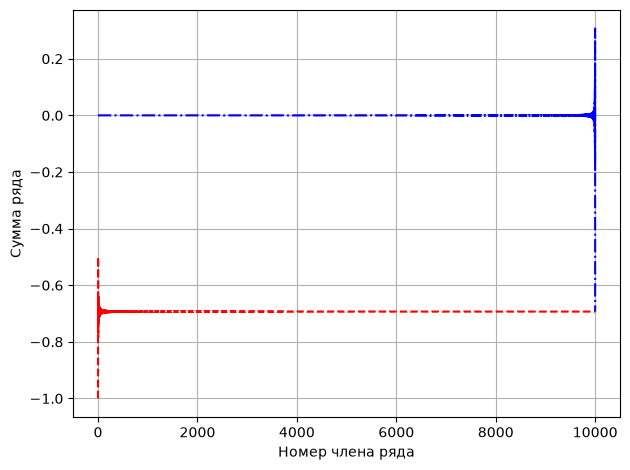

In [15]:
first_case_cumsum = np.cumsum(big_numbers)
second_case_cumsum = np.cumsum(small_numbers)

plt.plot(first_case_cumsum, color="red", linestyle="--")
plt.plot(second_case_cumsum, color="blue", linestyle="-.")
plt.xlabel("Номер члена ряда")
plt.ylabel("Сумма ряда")
plt.grid()
plt.tight_layout()
plt.show()

-1.2989609388114332e-14


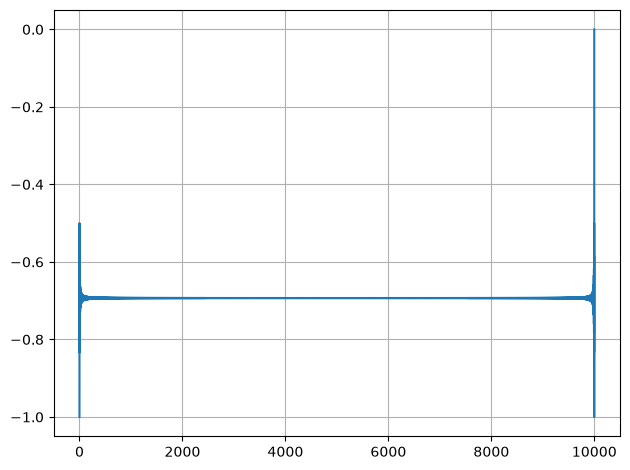

In [16]:
distances = [first_case_cumsum[i] - second_case_cumsum[i] for i in range(10000)]

print(distances[-1])

plt.plot(distances)
plt.tight_layout()
plt.grid()
plt.show()

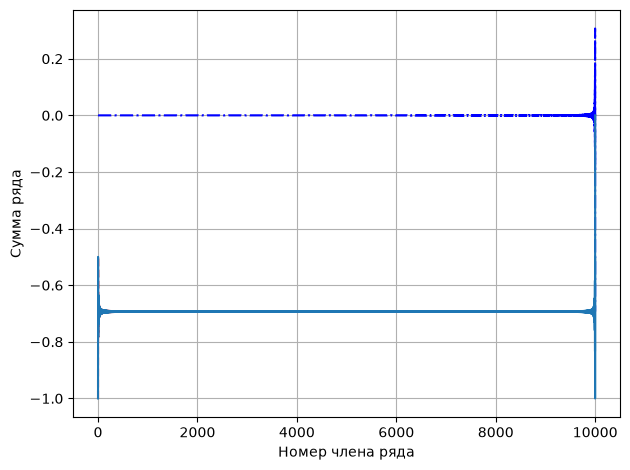

In [17]:
plt.plot(first_case_cumsum, color="red", linestyle="--")
plt.plot(second_case_cumsum, color="blue", linestyle="-.")
plt.plot(distances)
plt.xlabel("Номер члена ряда")
plt.ylabel("Сумма ряда")
plt.grid()
plt.tight_layout()
plt.show()

Найдем какой-нибудь эталон, чтобы понять, как из способов наиболее корректный.

Будем отталкиваться из того соображения, что все члены ряда $\in \mathbb{Q} \Longrightarrow \sum \in \mathbb{Q}$

Тогда и представим все слагаемые как рациональные дроби.

In [18]:
from fractions import Fraction
import math
import sys

sys.set_int_max_str_digits(1_000_000)   

exact_sum = sum(Fraction((-1)**n, n) for n in range(1, 10001))

reference = float(exact_sum)

print(f"Эталонная сумма: {reference}")
print(f"Числитель {exact_sum.numerator}")
print(f"Знаменатель {exact_sum.denominator}")

Эталонная сумма: -0.6930971830599453
Числитель -1042947378178129248828089347419281885091659606539365119923610047149917384281289600051441437188306017227391892557131405341839205212657626086349821692549618919204277730938886384019928187326684964954281859718934970690081275621376633775385823725305948833083720820207593946398222305763314297020032461168569032701510166561626230631522454891238245951308832634832324460672505895582369677782808343415003623577937445165940855564430653620180948420570073461456612051103138096021009108747752672809639418438903526012648759380804606996708225569742154452280494518942339771996250981294007257536542833810217570321742919033755937708128654744177011797865392200240846068022493773626103225773631407807407247343588890979276369917297199482284437271601905296405205123545465844352958442733106686151316169687256796783868264752811308830677007389482687536564126271300101833051651002714488057645270885816688489007739996539390968972563025321453211995677666821275598614649783115538302

In [19]:
import struct 

x = 1.0
bits_float = struct.pack('<d', x) #little-endian double (8-байтовое число с плав. точкой)
bits_int = struct.unpack('<Q', bits_float)[0] #распаковываем в unsigned long long
print(hex(bits_int))

print(format(bits_int, '064b'))
print()
print("S =", format(bits_int >> 63, 'b'))          
print("E =", format((bits_int >> 52) & 0x7FF, '011b'))  
print("F =", format(bits_int & ((1<<52)-1), '052b'))    

0x3ff0000000000000
0011111111110000000000000000000000000000000000000000000000000000

S = 0
E = 01111111111
F = 0000000000000000000000000000000000000000000000000000


S - 1 бит, E - 11 бит, F - 52 бита

Где $$x = (-1)^s \cdot (1 + \frac{F}{2^{52}}) \cdot 2^{E-1023}$$

$$x = (-1)^0 \cdot 1.0 \cdot 2^0 = 1.0$$

Соответственно $(-1)^s$ - **знак**
$(1 + \frac{F}{2^{52}})$ - **мантисса**
$2^{E-1023}$ - **масштаб**

In [20]:
def parts(x):
    bits = struct.unpack('<Q', struct.pack('<d', x))[0]
    S = bits >> 63
    E = (bits >> 52) & 0x7FF
    F = bits & ((1 << 52) - 1)
    return S, E, F, bits

S, E, F, bits = parts(reference)

print(f"reference = {reference!r}")
print(f"hex       = {hex(bits)}")
print(f"bits      = {format(bits, '064b')}")
print()
print(f"S = {S}")
print(f"E = {format(E, '011b')}  = {E}  (e_true = {E - 1023})")
print(f"F = {format(F, '052b')}")
print()
print(f"проверка: {(-1)**S * (1 + F/2**52) * 2**(E - 1023)}")

reference = -0.6930971830599453
hex       = 0xbfe62dda24c6266c
bits      = 1011111111100110001011011101101000100100110001100010011001101100

S = 1
E = 01111111110  = 1022  (e_true = -1)
F = 0110001011011101101000100100110001100010011001101100

проверка: -0.6930971830599453


Посмотрим на минимальный шаг, на который может отличаться референсное число от своего ближайшего соседа double (unit in the place)

In [21]:
ref_ulp = math.ulp(reference)        
print(f"ulp(reference) = {ref_ulp:.6e}")
print(f"                 = 2^{math.log2(ref_ulp):.0f}")

ulp(reference) = 1.110223e-16
                 = 2^-53


In [22]:
results = {
    "1. big → small":              first_case_sum,
    "2. small → big":              second_case_sum,
    "3. big → small (раздельно)":  third_case_sum,
    "4. small → big (раздельно)":  fourth_case_sum,
    "Python sum()":                Python_sum,
    "Fraction (эталон)":           reference,
}

print(f"{'метод':34s} {'значение':>22s} {'|err|':>11s} {'ulp':>8s}")

for name, val in results.items():
    err   = abs(val - reference)
    n_ulp = err / ref_ulp
    print(f"{name:34s} {val:22.17f} {err:11.3e} {n_ulp:8.2f}")

метод                                            значение       |err|      ulp
1. big → small                       -0.69309718305995827   1.299e-14   117.00
2. small → big                       -0.69309718305994528   0.000e+00     0.00
3. big → small (раздельно)           -0.69309718305995371   8.438e-15    76.00
4. small → big (раздельно)           -0.69309718305994839   3.109e-15    28.00
Python sum()                         -0.69309718305994528   0.000e+00     0.00
Fraction (эталон)                    -0.69309718305994528   0.000e+00     0.00


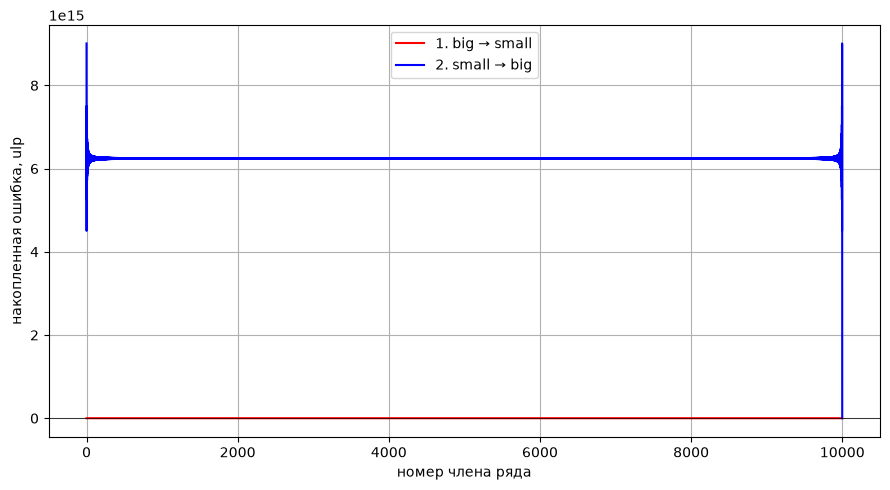

In [23]:
exact_prefix = []
s = Fraction(0)
for n in range(1, 10001):
    s += Fraction((-1)**n, n)
    exact_prefix.append(float(s))

exact_prefix = np.array(exact_prefix)

err_1 = first_case_cumsum  - exact_prefix
err_2 = second_case_cumsum - exact_prefix

plt.figure(figsize=(9, 5))
plt.plot(err_1 / ref_ulp, label="1. big → small",   color="red")
plt.plot(err_2 / ref_ulp, label="2. small → big",   color="blue")
plt.axhline(0, color="k", linewidth=0.5)
plt.xlabel("номер члена ряда")
plt.ylabel("накопленная ошибка, ulp")
plt.legend(); plt.grid(); plt.tight_layout(); plt.show()